In [12]:
import scipy.io
from netCDF4 import Dataset
import numpy as np
import datetime
import matplotlib.pyplot as plt
from regrid import regrid_fast
from matplotlib import gridspec
import glob
import xarray as xr
import tqdm
import cartopy.crs as ccrs
import itertools
import os
import cartopy
import warnings
warnings.filterwarnings("ignore")

In [2]:
landy_dates = [] ; landy_lons = [] ; landy_lats = [] ; landy_corrs = []

datapath = '/Users/carmennab/cpom_server/home/cjn/pb_new/along_track/'

for year in np.arange(2011,2023):
    file = f'rfb_bias_corr_{year}_apr_oct.mat'

    data = scipy.io.loadmat(f'{datapath}{file}')
    
    landy_corr = np.array(data['rfb_bias_corr'])
    
    days = np.arange(0,landy_corr.shape[2])
    dates = [datetime.date(year,5,1)+datetime.timedelta(days=int(days)) for days in days]
    
    for count,date in enumerate(dates):
        landy_dates.append(date) ; landy_corrs.append(landy_corr[:,:,count]) 

landy_lons = np.array(data['lon'])
landy_lats = np.array(data['lat'])
landy_weekly = np.array(landy_corrs)  

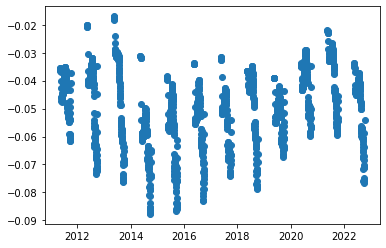

In [3]:
means = []
for count,date in enumerate(landy_dates):
    means.append(np.nanmean(landy_weekly[count]))
plt.scatter(landy_dates,means)

In [4]:
### load interp dates
days = np.arange(0,4749) # until 31/12/2022
dates = [datetime.date(2010,1,1)+datetime.timedelta(days=int(days)) for days in days]
interp_dates = [date.strftime('%Y%m%d') for date in dates]
str_dates = [date.strftime('%Y%m%d') for date in landy_dates]

### check for which dates we have Landy + interp data
landy_days = []
landy_daily = np.full((len(str_dates),361,361),np.nan)

for interp_day,interp_date in enumerate(interp_dates):
    for landy_day,landy_date in enumerate(str_dates):
        if landy_date == interp_date:
            landy_days.append(interp_day)

In [5]:
### interpolate weekly corr to daily corr
em_daily = np.full((len(days),landy_weekly.shape[1],landy_weekly.shape[2]), np.nan)

for i, j in tqdm.tqdm(itertools.product(np.arange(landy_weekly.shape[1]),
                              np.arange(landy_weekly.shape[2]))):
    em_daily[:,i,j] = np.interp(days,landy_days,landy_weekly[:,i,j]) 

130321it [00:26, 4846.52it/s]


In [6]:
### replace 2010 and interpolated winter corrs with 0s

for day,date in zip(days,interp_dates):
    if date[4:6] in ['10','11','12','01','02','03','04']:
        em_daily[day] = np.full((361,361),0)
        
for day,date in zip(days,interp_dates):
    if date[0:4] == '2010':
        em_daily[day] = np.full((361,361),0)

In [7]:
datapath = '/Users/carmennab/cpom_server/home/cjn/pb_new/auxiliary/'
ease_lats = np.array(np.load(datapath + 'lat_cent.npy'))
ease_lons = np.array(np.load(datapath + 'lon_cent.npy'))

em_corrections = regrid_fast(em_daily,landy_lons,landy_lats,ease_lons,ease_lats)

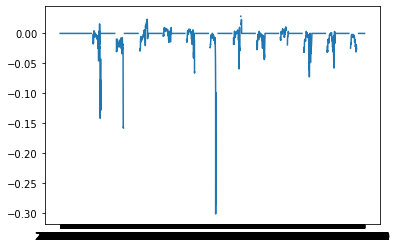

In [8]:
means = [np.nanmean(em) for em in em_corrections]
plt.plot(interp_dates,means)

In [9]:
em_corrections[np.isnan(em_corrections)] = 0

### save yearly netcdfs

In [14]:
for year in tqdm.trange(2010,2023):
    
    d1 = datetime.date(year, 1, 1)
    d2 = datetime.date(year, 12, 31)
    dates = [d1 + datetime.timedelta(days=x) for x in range((d2-d1).days + 1)]
    dates = [date.strftime('%Y%m%d') for date in dates]
    
    all_corrections = np.full((len(dates),84,103),np.nan)
    
    for date_count,date in enumerate(dates):
        
        for all_date_count,all_date in enumerate(interp_dates):
            if all_date == date:
                all_corrections[date_count] = em_corrections[all_date_count]

    ### create depth NETCDF
    filepath_out = f'{datapath}em_correction/{year}.nc'
    if os.path.exists(filepath_out) == True: 
        ! rm {filepath_out} 
    data_vars = {'em_correction':(['t','x','y'],all_corrections)}
    ds = xr.Dataset(data_vars = data_vars,
                    coords={'longitude':(['x','y'],ease_lons),
                            'latitude':(['x','y'],ease_lats),
                             'date':(['t'],dates)}     )
    ds.to_netcdf(filepath_out,'w')


100%|███████████████████████████████████████████| 13/13 [00:27<00:00,  2.10s/it]
